<a href="https://colab.research.google.com/github/smir-nat/IAD-Practicals/blob/main/lab3/lab_3_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завдання 1

Epoch [10/50] | Train Loss: 1.1893 | Val Loss: 1.1547
Epoch [20/50] | Train Loss: 1.1774 | Val Loss: 1.1667
Epoch [30/50] | Train Loss: 1.1586 | Val Loss: 1.1569
Epoch [40/50] | Train Loss: 1.1433 | Val Loss: 1.1542
Epoch [50/50] | Train Loss: 1.1336 | Val Loss: 1.1506


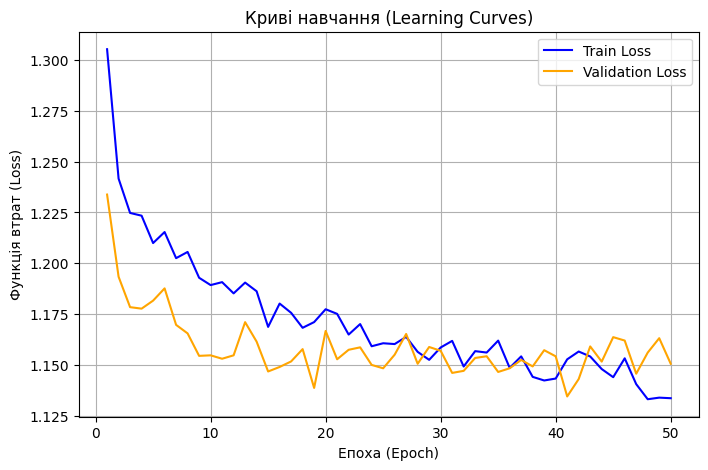


--- Результати класифікації (MLP PyTorch) ---
              precision    recall  f1-score   support

           0       0.98      0.69      0.81      1920
           1       0.08      0.65      0.14        80

    accuracy                           0.69      2000
   macro avg       0.53      0.67      0.48      2000
weighted avg       0.94      0.69      0.78      2000



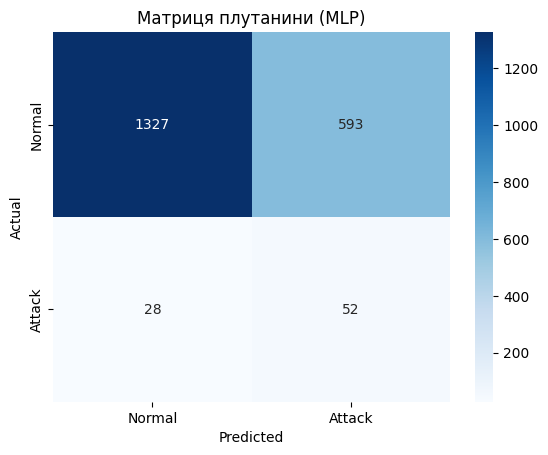

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

url = 'https://raw.githubusercontent.com/smir-nat/IAD-Practicals/main/lab2/cybersecurity.csv'
df = pd.read_csv(url)

cols_to_drop = ['timestamp', 'src_ip', 'dst_ip', 'url', 'attack_type']
df_clean = df.drop(columns=cols_to_drop)

le = LabelEncoder()
df_clean['protocol'] = le.fit_transform(df_clean['protocol'])
df_clean['user_agent'] = le.fit_transform(df_clean['user_agent'])
df_clean['is_internal_traffic'] = df_clean['is_internal_traffic'].astype(int)

X = df_clean.drop(columns=['label']).values
y = df_clean['label'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.FloatTensor(X_train_scaled)
y_train_t = torch.FloatTensor(y_train).view(-1, 1)
X_test_t = torch.FloatTensor(X_test_scaled)
y_test_t = torch.FloatTensor(y_test).view(-1, 1)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataset = TensorDataset(X_test_t, y_test_t)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

class MLP(nn.Module):
    def __init__(self, input_dim):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = MLP(input_dim=X_train.shape[1])

num_pos = y_train.sum()
num_neg = len(y_train) - num_pos
pos_weight = torch.tensor([num_neg / num_pos])

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    epoch_train_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item()
    train_losses.append(epoch_train_loss / len(train_loader))

    model.eval()
    epoch_val_loss = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            epoch_val_loss += loss.item()
    val_losses.append(epoch_val_loss / len(test_loader))

    if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs+1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, epochs+1), val_losses, label='Validation Loss', color='orange')
plt.title('Криві навчання (Learning Curves)')
plt.xlabel('Епоха (Epoch)')
plt.ylabel('Функція втрат (Loss)')
plt.legend()
plt.grid(True)
plt.show()

model.eval()
with torch.no_grad():
    y_pred_logits = model(X_test_t)
    y_pred = (torch.sigmoid(y_pred_logits) >= 0.5).float().numpy()

print("\n--- Результати класифікації (MLP PyTorch) ---")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title('Матриця плутанини (MLP)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Завдання 2

Класи: ['ants', 'bees']
Кількість тренувальних зображень: 244
Кількість валідаційних зображень: 153
Пристрій для навчання: cpu


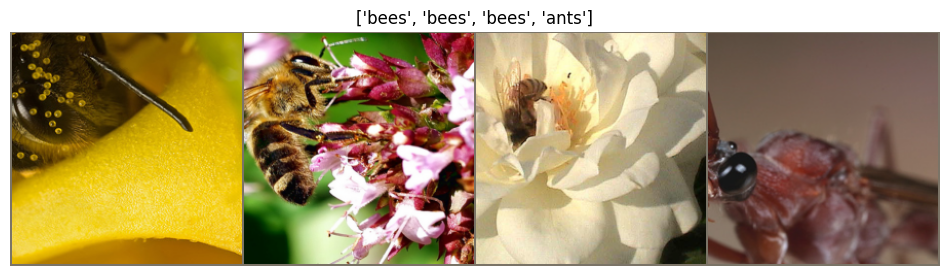

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
import os
import urllib.request
import zipfile
import time

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
zip_path = "hymenoptera_data.zip"
if not os.path.exists(zip_path):
    print("Завантаження датасету...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall()
    print("Датасет розпаковано!")

data_dir = 'hymenoptera_data'

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: DataLoader(image_datasets[x], batch_size=16, shuffle=True) for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Класи: {class_names}")
print(f"Кількість тренувальних зображень: {dataset_sizes['train']}")
print(f"Кількість валідаційних зображень: {dataset_sizes['val']}")
print(f"Пристрій для навчання: {device}")

def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.figure(figsize=(12, 6))
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

inputs, classes = next(iter(dataloaders['train']))
import torchvision
out = torchvision.utils.make_grid(inputs[:4])
imshow(out, title=[class_names[x] for x in classes[:4]])

In [5]:
# Функція для навчання моделі
def train_model(model, criterion, optimizer, num_epochs=15):
    start_time = time.time()
    train_loss_history, val_loss_history = [], []
    train_acc_history, val_acc_history = [], []

    for epoch in range(num_epochs):
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            if phase == 'train':
                train_loss_history.append(epoch_loss)
                train_acc_history.append(epoch_acc.item())
            else:
                val_loss_history.append(epoch_loss)
                val_acc_history.append(epoch_acc.item())

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss_history[-1]:.4f} Acc: {train_acc_history[-1]:.4f} | Val Loss: {val_loss_history[-1]:.4f} Acc: {val_acc_history[-1]:.4f}")

    time_elapsed = time.time() - start_time
    print(f'\nНавчання завершено за {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    return model, train_loss_history, val_loss_history, val_acc_history[-1]

# 1. Створюємо просту CNN
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # 3 згорткових шари + MaxPool
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Повнозв'язані шари (після трьох MaxPooling зображення 224x224 зменшується до 28x28)
        self.fc1 = nn.Linear(64 * 28 * 28, 128)
        self.fc2 = nn.Linear(128, 2)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1) # Flatten
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

print("--- Навчання простої CNN з нуля ---")
simple_cnn = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(simple_cnn.parameters(), lr=0.001)

simple_cnn, train_loss_cnn, val_loss_cnn, acc_cnn = train_model(simple_cnn, criterion, optimizer_cnn, num_epochs=15)

--- Навчання простої CNN з нуля ---
Epoch 1/15 | Train Loss: 0.8615 Acc: 0.5533 | Val Loss: 0.6692 Acc: 0.5817
Epoch 2/15 | Train Loss: 0.6444 Acc: 0.6066 | Val Loss: 0.6013 Acc: 0.6536
Epoch 3/15 | Train Loss: 0.6170 Acc: 0.6148 | Val Loss: 0.6600 Acc: 0.6013
Epoch 4/15 | Train Loss: 0.6138 Acc: 0.6066 | Val Loss: 0.5833 Acc: 0.6993
Epoch 5/15 | Train Loss: 0.5800 Acc: 0.6721 | Val Loss: 0.5994 Acc: 0.6667
Epoch 6/15 | Train Loss: 0.5720 Acc: 0.6803 | Val Loss: 0.5624 Acc: 0.7124
Epoch 7/15 | Train Loss: 0.5475 Acc: 0.6926 | Val Loss: 0.6236 Acc: 0.6405
Epoch 8/15 | Train Loss: 0.5560 Acc: 0.7008 | Val Loss: 0.5842 Acc: 0.6993
Epoch 9/15 | Train Loss: 0.5289 Acc: 0.7254 | Val Loss: 0.5722 Acc: 0.6993
Epoch 10/15 | Train Loss: 0.5335 Acc: 0.7049 | Val Loss: 0.5876 Acc: 0.6797
Epoch 11/15 | Train Loss: 0.5307 Acc: 0.7295 | Val Loss: 0.6057 Acc: 0.6732
Epoch 12/15 | Train Loss: 0.5480 Acc: 0.6885 | Val Loss: 0.6427 Acc: 0.6667
Epoch 13/15 | Train Loss: 0.5604 Acc: 0.6721 | Val Loss: 0.60


--- До-навчання (Fine-tuning) попередньо натренованої ResNet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 218MB/s]


Epoch 1/15 | Train Loss: 0.3949 Acc: 0.8197 | Val Loss: 0.2202 Acc: 0.9281
Epoch 2/15 | Train Loss: 0.2285 Acc: 0.9098 | Val Loss: 0.2182 Acc: 0.9412
Epoch 3/15 | Train Loss: 0.1630 Acc: 0.9303 | Val Loss: 0.2723 Acc: 0.9020
Epoch 4/15 | Train Loss: 0.1019 Acc: 0.9631 | Val Loss: 0.3044 Acc: 0.9150
Epoch 5/15 | Train Loss: 0.1133 Acc: 0.9631 | Val Loss: 0.3009 Acc: 0.9281
Epoch 6/15 | Train Loss: 0.1345 Acc: 0.9508 | Val Loss: 0.3714 Acc: 0.8954
Epoch 7/15 | Train Loss: 0.1399 Acc: 0.9426 | Val Loss: 0.2973 Acc: 0.9216
Epoch 8/15 | Train Loss: 0.1235 Acc: 0.9549 | Val Loss: 0.3085 Acc: 0.9216
Epoch 9/15 | Train Loss: 0.0867 Acc: 0.9754 | Val Loss: 0.2858 Acc: 0.9346
Epoch 10/15 | Train Loss: 0.1418 Acc: 0.9426 | Val Loss: 0.2579 Acc: 0.9216
Epoch 11/15 | Train Loss: 0.0912 Acc: 0.9672 | Val Loss: 0.2922 Acc: 0.8758
Epoch 12/15 | Train Loss: 0.1164 Acc: 0.9508 | Val Loss: 0.2948 Acc: 0.9216
Epoch 13/15 | Train Loss: 0.1048 Acc: 0.9467 | Val Loss: 0.3180 Acc: 0.9150
Epoch 14/15 | Train L

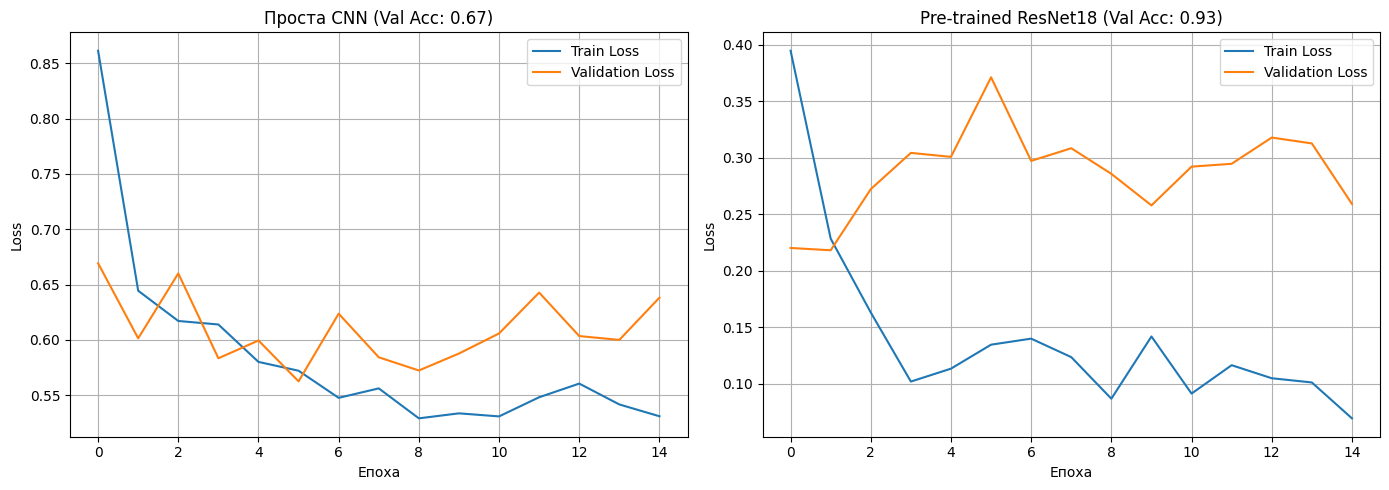

In [6]:
print("\n--- До-навчання (Fine-tuning) попередньо натренованої ResNet18 ---")
# 1. Завантажуємо ResNet18 з вагами ImageNet
pretrained_resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 2. Замінюємо останній шар класифікатора під наші 2 класи
num_ftrs = pretrained_resnet.fc.in_features
pretrained_resnet.fc = nn.Linear(num_ftrs, 2)
pretrained_resnet = pretrained_resnet.to(device)

optimizer_ft = optim.Adam(pretrained_resnet.parameters(), lr=0.0001) # Менший learning rate для transfer learning

pretrained_resnet, train_loss_res, val_loss_res, acc_res = train_model(pretrained_resnet, criterion, optimizer_ft, num_epochs=15)

# ==========================================
# Побудова Learning Curves для порівняння
# ==========================================
plt.figure(figsize=(14, 5))

# Графік для простої CNN
plt.subplot(1, 2, 1)
plt.plot(train_loss_cnn, label='Train Loss')
plt.plot(val_loss_cnn, label='Validation Loss')
plt.title(f'Проста CNN (Val Acc: {acc_cnn:.2f})')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Графік для ResNet18
plt.subplot(1, 2, 2)
plt.plot(train_loss_res, label='Train Loss')
plt.plot(val_loss_res, label='Validation Loss')
plt.title(f'Pre-trained ResNet18 (Val Acc: {acc_res:.2f})')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Завдання 3